<a href="https://colab.research.google.com/github/Edubel77/enrutaia/blob/main/notebooks/D3_lab_1_3_curvas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train : (50000, 28, 28) | Validación: (10000, 28, 28) | Test: (10000, 28, 28)
Rango de píxeles: 0.0 a 1.0
Ejemplos por clase en train: [5035 5029 4994 5014 5023 4970 4992 5014 5010 4919]


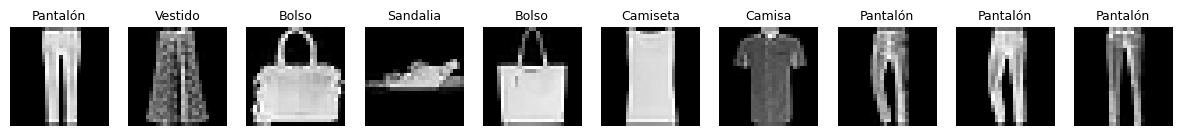

In [1]:
# Lab 1.3 - Paso 1: datos y los tres conjuntos
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

tf.keras.utils.set_random_seed(42)

(X_train_full, y_train_full), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()

# Escalar píxeles de 0-255 a 0-1 (igual que estandarizar ayer)
X_train_full = X_train_full.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Separar validación: barajar con semilla y tomar 10.000 para validar
idx = np.random.default_rng(42).permutation(len(X_train_full))
X_val,   y_val   = X_train_full[idx[:10_000]], y_train_full[idx[:10_000]]
X_train, y_train = X_train_full[idx[10_000:]], y_train_full[idx[10_000:]]

nombres = ["Camiseta", "Pantalón", "Suéter", "Vestido", "Abrigo",
           "Sandalia", "Camisa", "Tenis", "Bolso", "Botín"]

print("Train :", X_train.shape, "| Validación:", X_val.shape, "| Test:", X_test.shape)
print("Rango de píxeles:", X_train.min(), "a", X_train.max())
print("Ejemplos por clase en train:", np.bincount(y_train))

# Ver 10 ejemplos
fig, ax = plt.subplots(1, 10, figsize=(15, 2))
for i in range(10):
    ax[i].imshow(X_train[i], cmap="gray")
    ax[i].set_title(nombres[y_train[i]], fontsize=9)
    ax[i].axis("off")
plt.show()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Época final (20) -> train loss: 0.1627 | val loss: 0.3626 | train acc: 0.9405 | val acc: 0.8881
Mejor val loss en la época 11: 0.3122


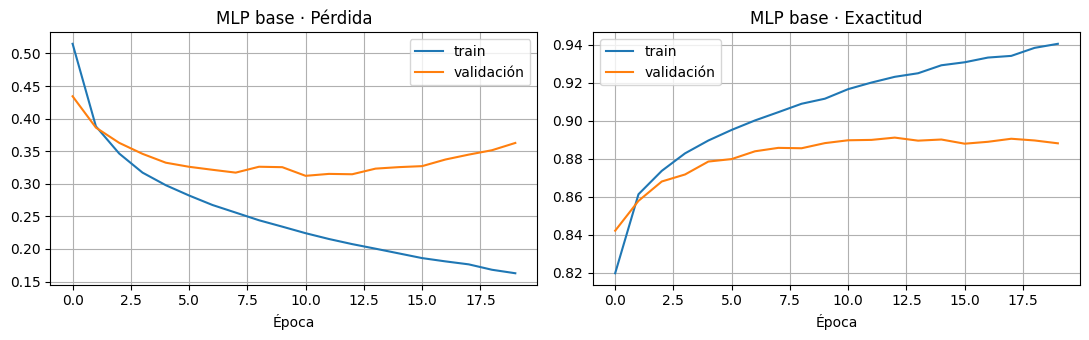

In [2]:
# Lab 1.3 - Paso 2: MLP base con validación
def graficar(historial, titulo):
    h = historial.history
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(h["loss"], label="train");    ax[0].plot(h["val_loss"], label="validación")
    ax[1].plot(h["accuracy"], label="train"); ax[1].plot(h["val_accuracy"], label="validación")
    ax[0].set_title(f"{titulo} · Pérdida"); ax[1].set_title(f"{titulo} · Exactitud")
    for a in ax: a.set_xlabel("Época"); a.legend(); a.grid(True)
    plt.tight_layout(); plt.show()

tf.keras.utils.set_random_seed(42)
modelo_base = keras.Sequential([
    keras.Input(shape=(28, 28)),
    keras.layers.Flatten(),                       # 28x28 -> 784
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax"), # 10 clases
])
modelo_base.compile(optimizer="adam",
                    loss="sparse_categorical_crossentropy",
                    metrics=["accuracy"])
modelo_base.summary()

hist_base = modelo_base.fit(X_train, y_train,
                            validation_data=(X_val, y_val),   # se evalúa al final de cada época
                            epochs=20, batch_size=32, verbose=0)

h = hist_base.history
mejor = int(np.argmin(h["val_loss"]))
print(f"Época final (20) -> train loss: {h['loss'][-1]:.4f} | val loss: {h['val_loss'][-1]:.4f} | "
      f"train acc: {h['accuracy'][-1]:.4f} | val acc: {h['val_accuracy'][-1]:.4f}")
print(f"Mejor val loss en la época {mejor + 1}: {h['val_loss'][mejor]:.4f}")

graficar(hist_base, "MLP base")

Parámetros: 932,362
Grande sin regul.  | train acc: 0.9530 | val acc: 0.8343 | brecha: 0.1187 | mejor val loss: 0.4591 (época 5) | val loss final: 0.7402


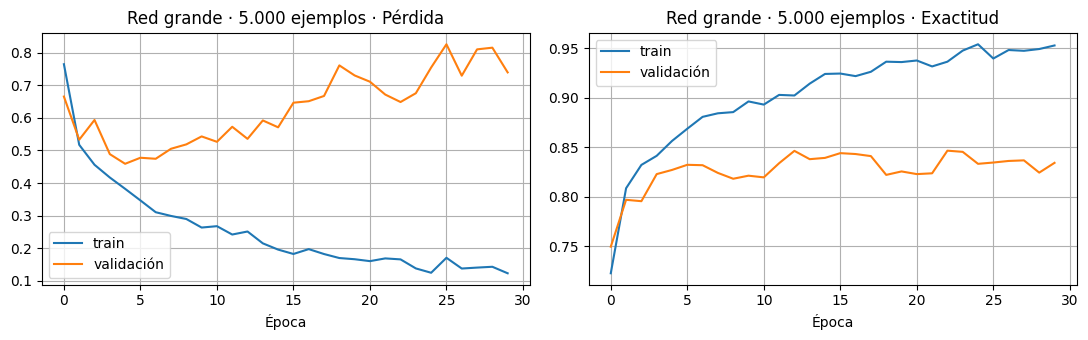

In [3]:
# Lab 1.3 - Paso 3: provocar sobreajuste
X_peq, y_peq = X_train[:5_000], y_train[:5_000]     # solo 5.000 ejemplos

def crear_grande(dropout=0.0, l2=0.0):
    tf.keras.utils.set_random_seed(42)
    reg = keras.regularizers.l2(l2) if l2 > 0 else None
    capas = [keras.Input(shape=(28, 28)), keras.layers.Flatten()]
    for _ in range(3):
        capas.append(keras.layers.Dense(512, activation="relu", kernel_regularizer=reg))
        if dropout > 0:
            capas.append(keras.layers.Dropout(dropout))
    capas.append(keras.layers.Dense(10, activation="softmax"))
    m = keras.Sequential(capas)
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

modelo_sobre = crear_grande()
print("Parámetros:", f"{modelo_sobre.count_params():,}")
hist_sobre = modelo_sobre.fit(X_peq, y_peq, validation_data=(X_val, y_val),
                              epochs=30, batch_size=32, verbose=0)

def resumen(nombre, hist):
    h = hist.history
    mejor = int(np.argmin(h["val_loss"]))
    print(f"{nombre:<18} | train acc: {h['accuracy'][-1]:.4f} | val acc: {h['val_accuracy'][-1]:.4f} | "
          f"brecha: {h['accuracy'][-1] - h['val_accuracy'][-1]:.4f} | "
          f"mejor val loss: {h['val_loss'][mejor]:.4f} (época {mejor + 1}) | val loss final: {h['val_loss'][-1]:.4f}")

resumen("Grande sin regul.", hist_sobre)
graficar(hist_sobre, "Red grande · 5.000 ejemplos")

Configuración        | épocas | train acc | val acc | brecha | val loss
Sin regularización   |     30 |    0.9312 |  0.8343 | 0.0969 | 0.7402
Dropout 0.3          |     30 |    0.9314 |  0.8548 | 0.0766 | 0.4763
L2 1e-4              |     30 |    0.9436 |  0.8440 | 0.0996 | 0.7494
EarlyStopping        |      8 |    0.8696 |  0.8271 | 0.0425 | 0.4591
Dropout + EarlyStop  |      3 |    0.7738 |  0.7611 | 0.0127 | 0.6179


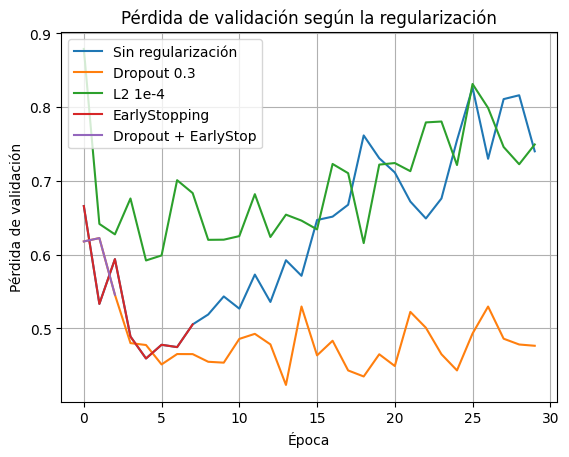

In [4]:
# Lab 1.3 - Paso 4: curar el sobreajuste
parar_a_tiempo = keras.callbacks.EarlyStopping(
    monitor="val_loss",          # vigila la pérdida de validación
    patience=3,                  # espera 3 épocas sin mejora antes de parar
    restore_best_weights=True)   # vuelve a los pesos de la mejor época

experimentos = {
    "Sin regularización": dict(dropout=0.0, l2=0.0,  callbacks=[]),
    "Dropout 0.3":        dict(dropout=0.3, l2=0.0,  callbacks=[]),
    "L2 1e-4":            dict(dropout=0.0, l2=1e-4, callbacks=[]),
    "EarlyStopping":      dict(dropout=0.0, l2=0.0,  callbacks=[parar_a_tiempo]),
    "Dropout + EarlyStop": dict(dropout=0.3, l2=0.0, callbacks=[parar_a_tiempo]),
}

historiales, filas = {}, []
for nombre, cfg in experimentos.items():
    m = crear_grande(dropout=cfg["dropout"], l2=cfg["l2"])
    h = m.fit(X_peq, y_peq, validation_data=(X_val, y_val), epochs=30,
              batch_size=32, verbose=0, callbacks=cfg["callbacks"])
    historiales[nombre] = h
    val_loss, val_acc = m.evaluate(X_val, y_val, verbose=0)       # el modelo que te quedarías
    train_loss, train_acc = m.evaluate(X_peq, y_peq, verbose=0)
    filas.append((nombre, len(h.history["loss"]), train_acc, val_acc, train_acc - val_acc, val_loss))

print(f"{'Configuración':<20} | épocas | train acc | val acc | brecha | val loss")
for n, ep, tr, va, br, vl in filas:
    print(f"{n:<20} | {ep:>6} | {tr:9.4f} | {va:7.4f} | {br:6.4f} | {vl:.4f}")

for nombre, h in historiales.items():
    plt.plot(h.history["val_loss"], label=nombre)
plt.xlabel("Época"); plt.ylabel("Pérdida de validación"); plt.legend(); plt.grid(True)
plt.title("Pérdida de validación según la regularización")
plt.show()

In [5]:
# Lab 1.3 - Paso 4b: diagnóstico del callback reutilizado
print("Mejor valor guardado en el callback:", parar_a_tiempo.best)

# Corrección: un callback NUEVO por experimento
def nuevo_early_stopping():
    return keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                         restore_best_weights=True)

m = crear_grande(dropout=0.3)
h = m.fit(X_peq, y_peq, validation_data=(X_val, y_val), epochs=30,
          batch_size=32, verbose=0, callbacks=[nuevo_early_stopping()])
val_loss, val_acc = m.evaluate(X_val, y_val, verbose=0)
train_loss, train_acc = m.evaluate(X_peq, y_peq, verbose=0)
print(f"Dropout + EarlyStop (corregido) | épocas: {len(h.history['loss'])} | train acc: {train_acc:.4f} | "
      f"val acc: {val_acc:.4f} | brecha: {train_acc - val_acc:.4f} | val loss: {val_loss:.4f}")

Mejor valor guardado en el callback: 0.4591142535209656
Dropout + EarlyStop (corregido) | épocas: 9 | train acc: 0.8720 | val acc: 0.8345 | brecha: 0.0375 | val loss: 0.4510


Parámetros Functional: 101,770 | Sequential (Paso 2): 101,770


Model: "dos_ramas"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_9       │ (None, 28, 28)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_9 (Flatten) │ (None, 784)       │          0 │ input_layer_9[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_33 (Dense)    │ (None, 64)        │     50,240 │ flatten_9[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_32 (Dense)    │ (None, 256)       │    200,960 │ flatten_9[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_34 (Dense)    │ (None, 64)        │      4,160 │ dense_33[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 320)       │          0 │ dense_32[0][0],   │
│ (Concatenate)       │                   │            │ dense_34[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_9 (Dropout) │ (None, 320)       │          0 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_35 (Dense)    │ (None, 10)        │      3,210 │ dropout_9[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 258,570 (1010.04 KB)

 Trainable params: 258,570 (1010.04 KB)

 Non-trainable params: 0 (0.00 B)

Dos ramas | épocas: 14 | val acc: 0.8925 | val loss: 0.2998


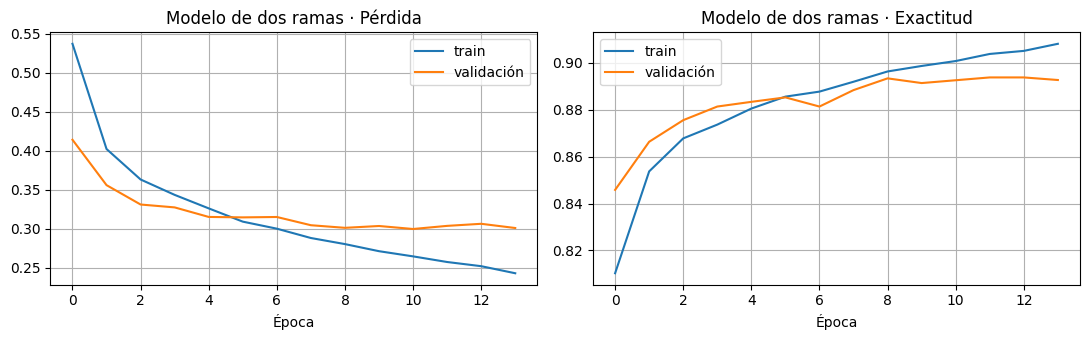

In [6]:
# Lab 1.3 - Paso 5: la API Functional

# A) El MISMO MLP base del Paso 2, escrito con la API Functional
tf.keras.utils.set_random_seed(42)
entrada = keras.Input(shape=(28, 28))
x = keras.layers.Flatten()(entrada)                 # capa(entrada) -> tensor
x = keras.layers.Dense(128, activation="relu")(x)
salida = keras.layers.Dense(10, activation="softmax")(x)
modelo_func = keras.Model(inputs=entrada, outputs=salida)
print("Parámetros Functional:", f"{modelo_func.count_params():,}",
      "| Sequential (Paso 2):", f"{modelo_base.count_params():,}")

# B) Algo que Sequential NO puede hacer: dos ramas que se unen
entrada = keras.Input(shape=(28, 28))
plano = keras.layers.Flatten()(entrada)
rama_ancha    = keras.layers.Dense(256, activation="relu")(plano)              # 1 capa ancha
rama_profunda = keras.layers.Dense(64, activation="relu")(plano)
rama_profunda = keras.layers.Dense(64, activation="relu")(rama_profunda)       # 2 capas estrechas
unidas = keras.layers.Concatenate()([rama_ancha, rama_profunda])               # unir ramas
unidas = keras.layers.Dropout(0.3)(unidas)
salida = keras.layers.Dense(10, activation="softmax")(unidas)
modelo_ramas = keras.Model(inputs=entrada, outputs=salida, name="dos_ramas")
modelo_ramas.summary()

modelo_ramas.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h = modelo_ramas.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30,
                     batch_size=32, verbose=0, callbacks=[nuevo_early_stopping()])
val_loss, val_acc = modelo_ramas.evaluate(X_val, y_val, verbose=0)
print(f"Dos ramas | épocas: {len(h.history['loss'])} | val acc: {val_acc:.4f} | val loss: {val_loss:.4f}")
graficar(h, "Modelo de dos ramas")


## Conclusiones de Regularización y Callbacks

| Configuración | Épocas | Train Acc | Val Acc | Brecha | Val Loss |
| :--- | :---: | :---: | :---: | :---: | :---: |
| Sin regularización | 30 | 0.9312 | 0.8343 | 0.0969 | 0.7402 |
| Dropout 0.3 | 30 | 0.9314 | 0.8548 | 0.0766 | 0.4763 |
| L2 1e-4 | 30 | 0.9436 | 0.8440 | 0.0996 | 0.7494 |
| EarlyStopping | 8 | 0.8696 | 0.8271 | 0.0425 | 0.4591 |
| **Dropout + EarlyStop (corregido)** | **9** | **0.8720** | **0.8345** | **0.0375** | **0.4510** |

**Configuración común:** red de 3 capas Dense(512), 5.000 ejemplos de entrenamiento, 10.000 de validación, semilla 42, Adam, hasta 30 épocas.

* **Elección y criterio:** con el criterio de **menor pérdida de validación** (0.4510) y **menor costo de cómputo** (9 épocas en lugar de 30), elijo **Dropout + EarlyStop**. Con el criterio de **exactitud de validación**, la mejor sería **Dropout 0.3** (0.8548 frente a 0.8345, unos 2 puntos más).
* **Lección del callback:** en la primera ejecución, "Dropout + EarlyStop" se detuvo en la época 3 porque se **reutilizó el mismo objeto `EarlyStopping`** del experimento anterior. El objeto conservaba internamente `best = 0.4591`, así que el nuevo entrenamiento no lograba superarlo y el contador de paciencia llegó a 3 de inmediato. Se confirmó imprimiendo `parar_a_tiempo.best` y se corrigió **creando un callback nuevo para cada entrenamiento** (`nuevo_early_stopping()`); con eso corrió 9 épocas.
* **Cómo funciona EarlyStopping:** deja correr `patience` épocas después del mejor valor de `val_loss` y, al detenerse, **restaura los pesos de la mejor época** (`restore_best_weights=True`).

**Limitaciones:**
* Una sola semilla: las diferencias pequeñas de pérdida (0.4510, 0.4591, 0.4763) podrían cambiar de orden con otras semillas.
* Se usaron solo 5.000 ejemplos para provocar sobreajuste; los resultados no son directamente comparables con modelos entrenados con los 50.000.